# Relatorio de Atrasos - Telemetria x Tabela Oficial URBS

**Periodo:** 09-12/09/2026 (qua-sab) | **Fontes:** telemetria GPS snapeada no shape + tabelaLinha oficial

**Metodo em uma linha:** para cada viagem programada (linha, tabela, NUM) e ponto de controle,
comparo o `HORA` previsto contra a mediana dos timestamps GPS a <= 200 m do ponto,
na janela de +-45 min do previsto. Positivo = atraso; negativo = adiantado.

## 1. Carregar os dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SAIDA = Path("outputs/atrasos")
df = pd.read_csv(SAIDA / "atrasos_por_ponto.csv", dtype={"COD": str})
res = pd.read_csv(SAIDA / "resumo_atrasos.csv")
# coluna lat/lon so existe se o atraso_tabela.py foi re-rodado com a versao com coordenadas
tem_geo = "lat" in df.columns
print(f"{len(df):,} observacoes | {df.COD.nunique()} linhas | {df.data.nunique()} dias")
print(f"Geo: {'sim' if tem_geo else 'NAO (rode o atraso_tabela.py novo para o mapa)'}")

11,807 observacoes | 11 linhas | 4 dias
Geo: sim


## 2. KPIs de cabecalho

In [2]:
from IPython.display import display
kpi = pd.DataFrame({
    "Mediana de atraso (min)": [round(df.atraso_min.median(), 1)],
    "P90 de atraso (min)": [round(df.atraso_min.quantile(0.90), 1)],
    "% dentro de +-5 min": [f"{100 * (df.atraso_min.abs() <= 5).mean():.0f}%"],
    "% atrasado >= 15 min": [f"{100 * (df.atraso_min >= 15).mean():.0f}%"],
    "Checkpoints observados": [f"{len(df):,}"],
})
display(kpi)
display(res)

,Mediana de atraso (min),P90 de atraso (min),% dentro de +-5 min,% atrasado >= 15 min,Checkpoints observados
0,-1.0,10.0,55%,5%,"11,807"


,data,DIA,pontos_casados,linhas,atraso_mediano_min,atraso_p90_min
0,2026-09-09,1,3107,10,0.0,12.0
1,2026-09-10,1,3175,11,-1.0,9.0
2,2026-09-11,1,3172,11,-1.0,9.0
3,2026-09-12,2,2353,11,-1.0,11.0


## 3. Distribuicao de atraso por linha

C:\Users\lilian retori\AppData\Local\Temp\ipykernel_15388\426865518.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df[df.COD == c].atraso_min.clip(-30, 60) for c in ordem],


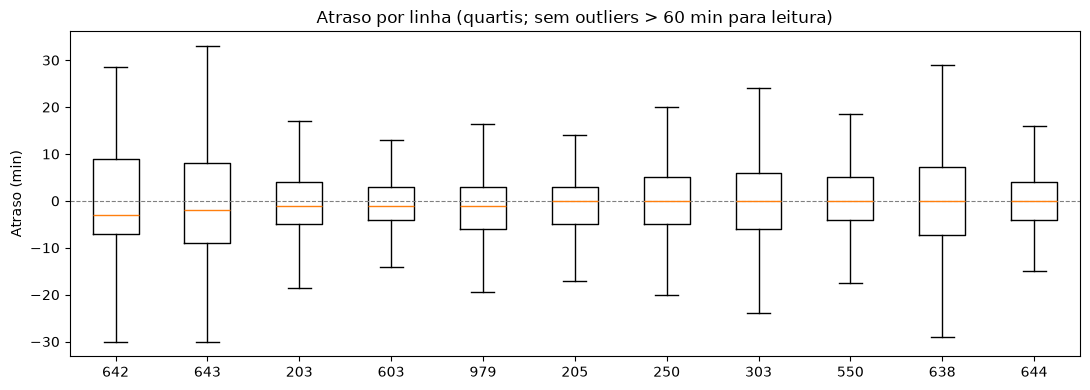

In [3]:
ordem = df.groupby("COD").atraso_min.median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([df[df.COD == c].atraso_min.clip(-30, 60) for c in ordem],
           tick_labels=ordem, showfliers=False, vert=True)
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_ylabel("Atraso (min)")
ax.set_title("Atraso por linha (quartis; sem outliers > 60 min para leitura)")
plt.tight_layout(); plt.show()

## 4. Quando o atraso acontece - heatmap linha x faixa horaria

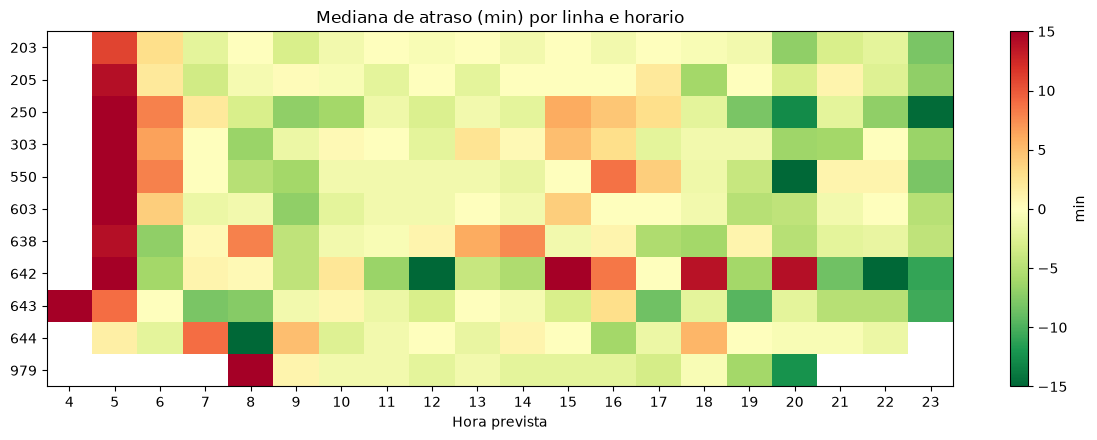

In [4]:
df["hora"] = pd.to_datetime(df.previsto, format="%H:%M").dt.hour
piv = df.pivot_table(index="COD", columns="hora", values="atraso_min", aggfunc="median")
fig, ax = plt.subplots(figsize=(12, 4.5))
vmax = 15
im = ax.imshow(piv, aspect="auto", cmap="RdYlGn_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
ax.set_xlabel("Hora prevista"); ax.set_title("Mediana de atraso (min) por linha e horario")
fig.colorbar(im, ax=ax, label="min")
plt.tight_layout(); plt.show()

## 5. Mapa dos checkpoints (mediana de atraso)

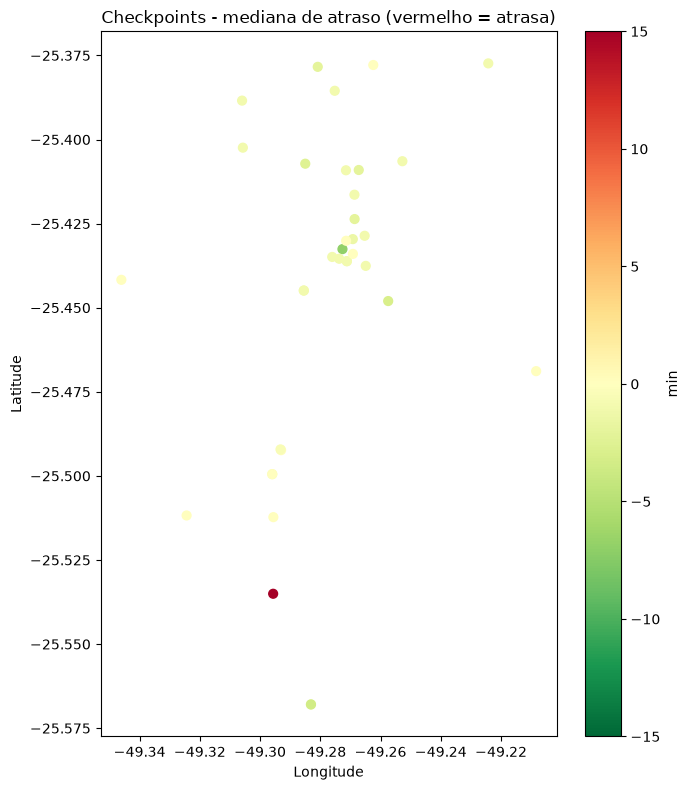

In [5]:
if tem_geo:
    pts = df.groupby(["PONTO", "lat", "lon"]).atraso_min.median().reset_index()
    fig, ax = plt.subplots(figsize=(7, 8))
    sc = ax.scatter(pts.lon, pts.lat, c=pts.atraso_min, cmap="RdYlGn_r",
                    vmin=-15, vmax=15, s=40)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title("Checkpoints - mediana de atraso (vermelho = atrasa)")
    fig.colorbar(sc, ax=ax, label="min")
    plt.tight_layout(); plt.show()
else:
    print("Sem colunas lat/lon: re-rode `python atraso_tabela.py --datas ...` com a versao "
          "nova para gerar o mapa. Os outros 2 visuais funcionam com o CSV atual.")

## 6. Notas e limitacoes

- Amostra: ~11 linhas, 4 dias. Numero exploratorio, nao o punho oficial.
- DIA 1 = seg-sex (09-11/09); DIA 2 = sabado (12/09). [Inferencia sobre a tabela URBS]
- 14% dos pontos da tabela nao tem coordenada (faltou o arquivo `pois` no coletor);
  cobertura das linhas amostradas nao foi afetada.
- "Seg-sex/sab/dom" presume a convencao URBS de DIA; confirme com a URBS antes da entrega final.